# 04 — Classificação supervisionada: o município é apto para a cultura?

Para cada cultura, um modelo binário responde **apto ou não apto** a partir do clima e da localização do município. Em seguida, uma classificação multiclasse indica a **cultura dominante**.

**Rótulo:** apto = área colhida média de 2015–2024 de pelo menos `LIMITE_HA` hectares (definido no notebook 00).

**Validação espacial:** os municípios são agrupados em células de 1° x 1° (cerca de 110 km) e a validação cruzada nunca deixa células iguais em treino e teste ao mesmo tempo. Sem isso, municípios vizinhos (com clima quase idêntico) vazariam informação do treino para o teste e a acurácia ficaria inflada.

**Métricas:** matriz de confusão, acurácia, precisão, recall, F1, acurácia balanceada e AUC. Como a classe "apto" é minoritária, a acurácia é comparada com o **baseline** de responder sempre "não apto".

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

df = pd.read_csv('../data/processed/dataset_municipios.csv')
culturas = ['Café', 'Cana-de-açúcar', 'Feijão', 'Laranja', 'Milho', 'Soja']
clima = ['temp_media', 'temp_min', 'chuva_anual', 'umidade', 'radiacao', 'amplitude_termica', 'contraste_chuva', 'chuva_seca']
geo = ['latitude', 'longitude']
df['celula'] = df['latitude'].round(0).astype(int).astype(str) + '_' + df['longitude'].round(0).astype(int).astype(str)
print(df.shape, '| células espaciais:', df['celula'].nunique())

(1576, 32) | células espaciais: 96


In [2]:
modelos = {
    'Regressão logística': make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight='balanced')),
    'Random Forest': RandomForestClassifier(400, min_samples_leaf=2, class_weight='balanced', random_state=0, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=250, random_state=0),
}
cv = GroupKFold(n_splits=5)

def avaliar(X, y, grupos):
    linhas, preds, probas = [], {}, {}
    for nome, m in modelos.items():
        p = cross_val_predict(m, X, y, cv=cv, groups=grupos)
        pr = cross_val_predict(m, X, y, cv=cv, groups=grupos, method='predict_proba')[:, 1]
        preds[nome], probas[nome] = p, pr
        linhas.append({'modelo': nome, 'acuracia': accuracy_score(y, p), 'acuracia_balanceada': balanced_accuracy_score(y, p),
                       'precisao': precision_score(y, p), 'recall': recall_score(y, p), 'f1': f1_score(y, p),
                       'auc': roc_auc_score(y, pr)})
    return pd.DataFrame(linhas).round(3), preds, probas

## 1. Um modelo por cultura

Comparamos **só com clima** e **clima + localização (latitude e longitude)**. O melhor modelo de cada cultura é escolhido pela **acurácia balanceada**, que não é inflada pela classe majoritária.

In [3]:
resultados, melhores = [], {}
for c in culturas:
    y = df['apto_' + c]
    baseline = max(y.mean(), 1 - y.mean())
    for cenario, fs in {'clima': clima, 'clima + localização': clima + geo}.items():
        tab, preds, probas = avaliar(df[fs], y, df['celula'])
        tab.insert(0, 'cenario', cenario); tab.insert(0, 'cultura', c)
        tab['baseline_acuracia'] = round(baseline, 3); tab['pct_aptos'] = round(y.mean() * 100, 1)
        resultados.append(tab)
        top = tab.sort_values('acuracia_balanceada').iloc[-1]
        chave = (c, cenario)
        melhores[chave] = {'modelo': top['modelo'], 'pred': preds[top['modelo']], 'proba': probas[top['modelo']], 'bal': top['acuracia_balanceada']}
res = pd.concat(resultados, ignore_index=True)
res.to_csv('../data/processed/classificacao_todos_modelos.csv', index=False)
res.sort_values(['cultura', 'cenario', 'acuracia_balanceada'], ascending=[True, True, False]).head(12)

,cultura,cenario,modelo,acuracia,acuracia_balanceada,precisao,recall,f1,auc,baseline_acuracia,pct_aptos
1,Café,clima,Random Forest,0.857,0.800,0.694,0.694,0.694,0.884,0.766,23.4
2,Café,clima,Gradient Boosting,0.867,0.780,0.768,0.618,0.685,0.894,0.766,23.4
0,Café,clima,Regressão logística,0.726,0.719,0.446,0.707,0.547,0.779,0.766,23.4
4,Café,clima + localização,Random Forest,0.879,0.811,0.775,0.683,0.726,0.903,0.766,23.4
5,Café,clima + localização,Gradient Boosting,0.877,0.793,0.799,0.634,0.707,0.902,0.766,23.4
3,Café,clima + localização,Regressão logística,0.715,0.702,0.431,0.678,0.527,0.772,0.766,23.4
7,Cana-de-açúcar,clima,Random Forest,0.911,0.906,0.862,0.888,0.875,0.947,0.647,35.3
8,Cana-de-açúcar,clima,Gradient Boosting,0.900,0.894,0.845,0.876,0.860,0.946,0.647,35.3
6,Cana-de-açúcar,clima,Regressão logística,0.885,0.877,0.826,0.853,0.839,0.931,0.647,35.3
11,Cana-de-açúcar,clima + localização,Gradient Boosting,0.918,0.906,0.894,0.869,0.881,0.948,0.647,35.3


## 2. Melhor resultado por cultura

In [4]:
melhor = (res.sort_values('acuracia_balanceada', ascending=False).groupby('cultura', as_index=False).first()
          .set_index('cultura').loc[culturas].reset_index())
melhor = melhor[['cultura', 'cenario', 'modelo', 'pct_aptos', 'baseline_acuracia', 'acuracia', 'acuracia_balanceada',
                 'precisao', 'recall', 'f1', 'auc']]
melhor.to_csv('../data/processed/classificacao_melhores.csv', index=False)
melhor

,cultura,cenario,modelo,pct_aptos,baseline_acuracia,acuracia,acuracia_balanceada,precisao,recall,f1,auc
0,Café,clima + localização,Random Forest,23.4,0.766,0.879,0.811,0.775,0.683,0.726,0.903
1,Cana-de-açúcar,clima + localização,Gradient Boosting,35.3,0.647,0.918,0.906,0.894,0.869,0.881,0.948
2,Feijão,clima + localização,Regressão logística,10.8,0.892,0.678,0.665,0.197,0.647,0.303,0.680
3,Laranja,clima,Regressão logística,10.2,0.898,0.736,0.801,0.263,0.882,0.406,0.816
4,Milho,clima + localização,Gradient Boosting,35.4,0.646,0.734,0.699,0.635,0.582,0.607,0.776
5,Soja,clima + localização,Random Forest,28.7,0.713,0.803,0.792,0.629,0.766,0.691,0.896


## 3. Matrizes de confusão (melhor modelo de cada cultura)

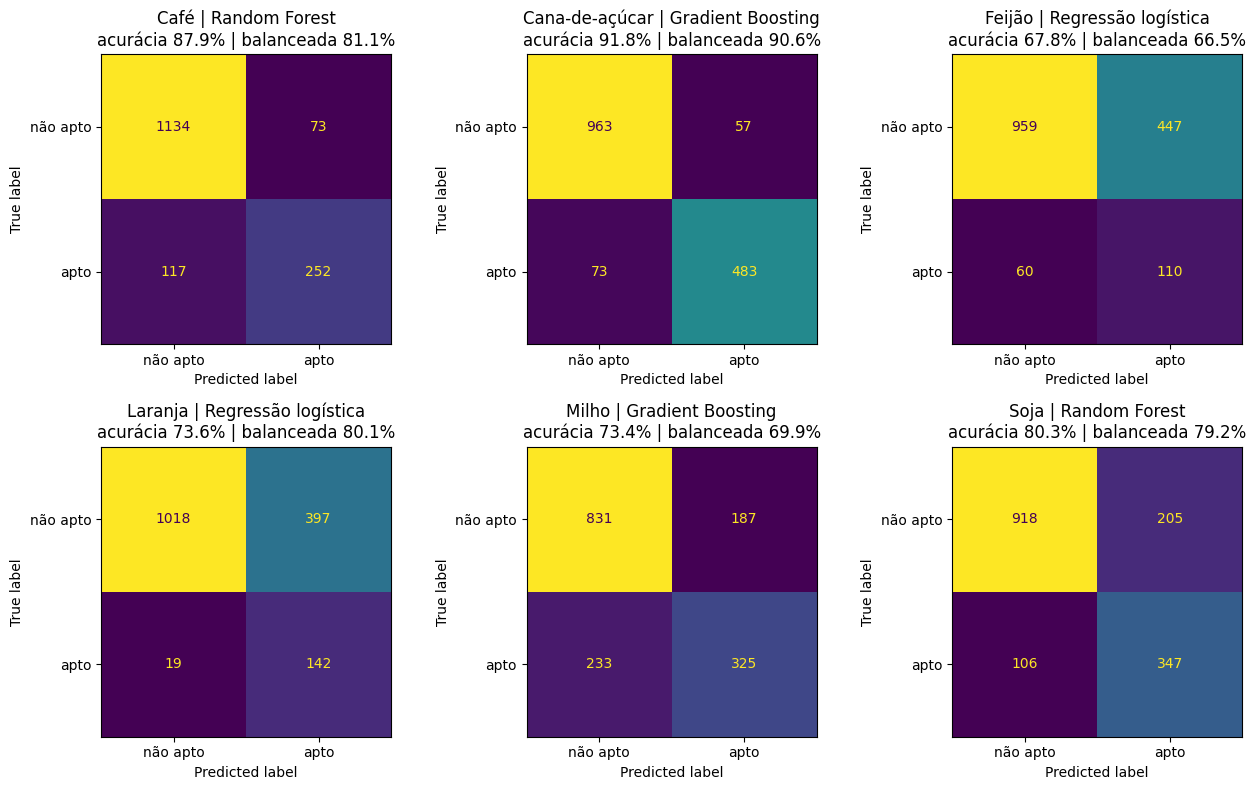

In [5]:
fig, eixos = plt.subplots(2, 3, figsize=(13, 8))
for ax, (_, r) in zip(eixos.ravel(), melhor.iterrows()):
    y = df['apto_' + r['cultura']]
    pred = melhores[(r['cultura'], r['cenario'])]['pred']
    cm = confusion_matrix(y, pred)
    ConfusionMatrixDisplay(cm, display_labels=['não apto', 'apto']).plot(ax=ax, colorbar=False, values_format='d')
    ax.set_title(f"{r['cultura']} | {r['modelo']}\nacurácia {r['acuracia']:.1%} | balanceada {r['acuracia_balanceada']:.1%}")
plt.tight_layout(); plt.savefig('../data/processed/matrizes_confusao.png', bbox_inches='tight'); plt.show()

In [6]:
linhas = []
for _, r in melhor.iterrows():
    y = df['apto_' + r['cultura']]
    tn, fp, fn, tp = confusion_matrix(y, melhores[(r['cultura'], r['cenario'])]['pred']).ravel()
    linhas.append({'cultura': r['cultura'], 'verdadeiro_negativo': tn, 'falso_positivo': fp, 'falso_negativo': fn, 'verdadeiro_positivo': tp})
pd.DataFrame(linhas).to_csv('../data/processed/matrizes_confusao.csv', index=False)
pd.DataFrame(linhas)

,cultura,verdadeiro_negativo,falso_positivo,falso_negativo,verdadeiro_positivo
0,Café,1134,73,117,252
1,Cana-de-açúcar,963,57,73,483
2,Feijão,959,447,60,110
3,Laranja,1018,397,19,142
4,Milho,831,187,233,325
5,Soja,918,205,106,347


## 4. Sensibilidade ao limite de "apto"

O limite de 500 ha é uma escolha. Abaixo, o mesmo modelo (gradient boosting, clima + localização) com outros limites, para mostrar quanto o resultado depende dele.

In [7]:
sens = []
for lim in (200, 500, 1000):
    for c in culturas:
        y = (df['area_' + c] >= lim).astype(int)
        if y.sum() < 30:
            continue
        p = cross_val_predict(modelos['Gradient Boosting'], df[clima + geo], y, cv=cv, groups=df['celula'])
        sens.append({'limite_ha': lim, 'cultura': c, 'pct_aptos': round(y.mean() * 100, 1),
                     'baseline': round(max(y.mean(), 1 - y.mean()), 3),
                     'acuracia': round(accuracy_score(y, p), 3), 'acuracia_balanceada': round(balanced_accuracy_score(y, p), 3)})
sens = pd.DataFrame(sens)
sens.to_csv('../data/processed/classificacao_sensibilidade_limite.csv', index=False)
sens.pivot(index='cultura', columns='limite_ha', values='acuracia_balanceada')

limite_ha,200,500,1000
cultura,,,
Café,0.810,0.793,0.799
Cana-de-açúcar,0.867,0.906,0.915
Feijão,0.678,0.619,0.587
Laranja,0.787,0.666,0.628
Milho,0.682,0.699,0.705
Soja,0.814,0.755,0.755


## 5. Quais variáveis pesam (importância por permutação, Random Forest)

In [8]:
from sklearn.inspection import permutation_importance
imp = {}
for c in culturas:
    y = df['apto_' + c]
    rf = RandomForestClassifier(400, min_samples_leaf=2, class_weight='balanced', random_state=0, n_jobs=-1).fit(df[clima + geo], y)
    r = permutation_importance(rf, df[clima + geo], y, n_repeats=5, random_state=0, scoring='balanced_accuracy', n_jobs=-1)
    imp[c] = pd.Series(r.importances_mean, index=clima + geo)
imp = pd.DataFrame(imp).round(3)
imp.to_csv('../data/processed/classificacao_importancia_variaveis.csv')
imp

,Café,Cana-de-açúcar,Feijão,Laranja,Milho,Soja
temp_media,0.035,0.010,0.134,0.035,0.030,0.010
temp_min,0.021,0.028,0.073,0.211,0.029,0.023
chuva_anual,0.010,0.002,0.038,0.047,0.016,0.007
umidade,0.071,0.003,0.060,0.015,0.044,0.017
radiacao,0.086,0.018,0.083,0.142,0.060,0.054
amplitude_termica,0.027,0.001,0.118,0.062,0.031,0.012
contraste_chuva,0.014,0.005,0.091,0.020,0.015,0.012
chuva_seca,0.016,0.004,0.267,0.070,0.044,0.023
latitude,0.108,0.019,0.181,0.202,0.118,0.072
longitude,0.177,0.270,0.298,0.379,0.213,0.248


## 6. Cultura dominante (multiclasse)

Qual das seis culturas tem a maior área no município, ou nenhuma. É um problema de várias classes e mais difícil que o sim ou não.

baseline (classe mais comum): 0.369
acurácia: 0.72 | acurácia balanceada: 0.508


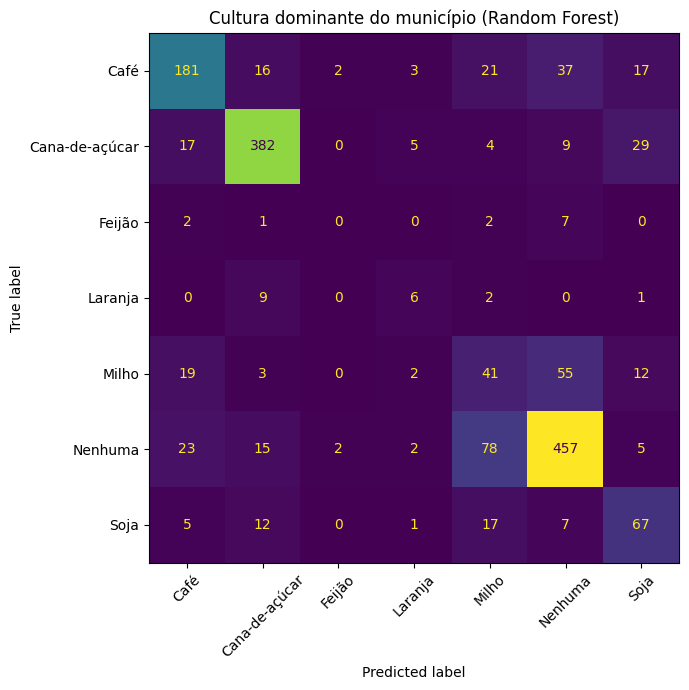

In [9]:
y_dom = df['cultura_dominante']
fs = clima + geo
mc = RandomForestClassifier(500, min_samples_leaf=2, class_weight='balanced', random_state=0, n_jobs=-1)
pred_dom = cross_val_predict(mc, df[fs], y_dom, cv=cv, groups=df['celula'])
classes = sorted(y_dom.unique())
base = y_dom.value_counts(normalize=True).max()
print('baseline (classe mais comum):', round(base, 3))
print('acurácia:', round(accuracy_score(y_dom, pred_dom), 3), '| acurácia balanceada:', round(balanced_accuracy_score(y_dom, pred_dom), 3))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_dom, pred_dom, labels=classes), display_labels=classes).plot(ax=ax, colorbar=False, xticks_rotation=45)
ax.set_title('Cultura dominante do município (Random Forest)')
plt.tight_layout(); plt.savefig('../data/processed/matriz_confusao_multiclasse.png', bbox_inches='tight'); plt.show()
pd.DataFrame(confusion_matrix(y_dom, pred_dom, labels=classes), index=classes, columns=classes).to_csv('../data/processed/matriz_confusao_multiclasse.csv')

## 7. Recomendação por município

A **compatibilidade** de cada cultura é a probabilidade de "apto" prevista pelo melhor modelo da cultura. Ela é calculada **fora da amostra** (cada município é previsto por um modelo que não o viu nem viu os vizinhos da mesma célula), então o valor é honesto.

In [10]:
linhas = []
for _, r in melhor.iterrows():
    proba = melhores[(r['cultura'], r['cenario'])]['proba']
    tmp = df[['cod', 'municipio', 'uf']].copy()
    tmp['cultura'] = r['cultura']; tmp['compatibilidade'] = proba.round(3); tmp['apto_real'] = df['apto_' + r['cultura']]
    linhas.append(tmp)
comp = pd.concat(linhas, ignore_index=True)
comp['ranking'] = comp.groupby('cod')['compatibilidade'].rank(ascending=False, method='first').astype(int)
comp = comp.sort_values(['cod', 'ranking'])
comp.to_csv('../data/processed/compatibilidade_culturas.csv', index=False)
comp.head(12)

,cod,municipio,uf,cultura,compatibilidade,apto_real,ranking
7880,3100104,Abadia dos Dourados,MG,Soja,0.997,1,1
0,3100104,Abadia dos Dourados,MG,Café,0.741,0,2
3152,3100104,Abadia dos Dourados,MG,Feijão,0.711,0,3
6304,3100104,Abadia dos Dourados,MG,Milho,0.665,1,4
4728,3100104,Abadia dos Dourados,MG,Laranja,0.356,0,5
1576,3100104,Abadia dos Dourados,MG,Cana-de-açúcar,0.051,0,6
3153,3100203,Abaeté,MG,Feijão,0.495,0,1
7881,3100203,Abaeté,MG,Soja,0.171,0,2
4729,3100203,Abaeté,MG,Laranja,0.166,0,3
6305,3100203,Abaeté,MG,Milho,0.103,1,4


In [11]:
exemplos = ['Patrocínio', 'Varginha', 'Campinas', 'Ribeirão Preto', 'Vitória', 'Franca']
comp[comp['municipio'].isin(exemplos) & (comp['ranking'] <= 3)][['municipio', 'uf', 'ranking', 'cultura', 'compatibilidade', 'apto_real']]

,municipio,uf,ranking,cultura,compatibilidade,apto_real
8906,Patrocínio,MG,1,Soja,0.910,1
4178,Patrocínio,MG,2,Feijão,0.881,1
7330,Patrocínio,MG,3,Milho,0.834,1
1542,Varginha,MG,1,Café,0.995,1
9422,Varginha,MG,2,Soja,0.924,0
7846,Varginha,MG,3,Milho,0.843,0
1569,Vitória,ES,1,Café,0.983,0
4721,Vitória,ES,2,Feijão,0.340,0
7873,Vitória,ES,3,Milho,0.099,0
1821,Campinas,SP,1,Cana-de-açúcar,0.931,1
